In [5]:
import os
import shutil
import random
from pathlib import Path
import cv2
import numpy as np
import matplotlib.pyplot as plt
import torch
from ultralytics import YOLO, SAM

# 1. Проверка GPU
device = "cuda" if torch.cuda.is_available() else "cpu"
print(f"Устройство: {device}")
if device == "cuda":
    print(f"GPU: {torch.cuda.get_device_name(0)} (VRAM: {torch.cuda.get_device_properties(0).total_memory / 1024**3:.1f} GB)")

# 2. Пути проекта
MEDISEG_DIR = Path(r"D:\Tabmed\Datasets\MEDISEG\32pills")
MEDISEG_IMG_DIR = MEDISEG_DIR / "images"
MEDISEG_LBL_DIR = MEDISEG_DIR / "labels_yolo_seg"

V5_DIR = Path(r"D:\Tabmed\Datasets\dataset_v5_balanced")
OUT_DIR = Path(r"D:\Tabmed\Datasets\dataset_v6_seg")

print(f"MEDISEG найден: {MEDISEG_DIR.exists()} ({MEDISEG_DIR})")
print(f"dataset_v5_balanced найден: {V5_DIR.exists()}")

Устройство: cuda
GPU: NVIDIA GeForce RTX 4060 Ti (VRAM: 16.0 GB)
MEDISEG найден: True (D:\Tabmed\Datasets\MEDISEG\32pills)
dataset_v5_balanced найден: True


In [6]:
random.seed(42)

# Создаем базовую временную структуру
TEMP_IMG = OUT_DIR / "_raw_images"
TEMP_LBL = OUT_DIR / "_raw_labels"
TEMP_IMG.mkdir(parents=True, exist_ok=True)
TEMP_LBL.mkdir(parents=True, exist_ok=True)

mediseg_txts = list(MEDISEG_LBL_DIR.glob("*.txt"))
sample_size = min(200, len(mediseg_txts))
sampled_mediseg = random.sample(mediseg_txts, sample_size)

mediseg_added = 0
for txt_p in sampled_mediseg:
    img_candidates = [
        MEDISEG_IMG_DIR / f"{txt_p.stem}.jpg",
        MEDISEG_IMG_DIR / f"{txt_p.stem}.png"
    ]
    img_p = next((p for p in img_candidates if p.exists()), None)
    
    if img_p:
        shutil.copy2(img_p, TEMP_IMG / f"mediseg_{img_p.name}")
        shutil.copy2(txt_p, TEMP_LBL / f"mediseg_{txt_p.name}")
        mediseg_added += 1

print(f"Отобрано и скопировано из MEDISEG: {mediseg_added} файлов.")

Отобрано и скопировано из MEDISEG: 200 файлов.


In [9]:
print("Инициализация SAM 2 (sam2_b.pt)...")
sam_model = SAM("sam2_b.pt")

v5_images = [p for p in (V5_DIR / "images").rglob("*.*") if p.suffix.lower() in [".jpg", ".jpeg", ".png"]]
total_imgs = len(v5_images)
print(f"Найдено фото в dataset_v5_balanced: {total_imgs}")

v5_added = 0
for idx, img_path in enumerate(v5_images, 1):
    rel_p = img_path.relative_to(V5_DIR / "images")
    lbl_path = V5_DIR / "labels" / rel_p.parent / f"{img_path.stem}.txt"
    
    if not lbl_path.exists():
        continue

    img = cv2.imread(str(img_path))
    if img is None:
        continue
    h, w = img.shape[:2]

    with open(lbl_path, "r", encoding="utf-8") as f:
        lines = [line.strip().split() for line in f if line.strip()]

    seg_annotations = []
    for line in lines:
        cls_id = int(line[0])
        xc, yc, bw, bh = map(float, line[1:5])

        # Перевод в абсолютные координаты рамки для SAM 2
        x1 = max(0, int((xc - bw / 2.0) * w))
        y1 = max(0, int((yc - bh / 2.0) * h))
        x2 = min(w - 1, int((xc + bw / 2.0) * w))
        y2 = min(h - 1, int((yc + bh / 2.0) * h))

        # Защита от вырожденных рамок
        if (x2 - x1) < 4 or (y2 - y1) < 4:
            continue

        try:
            res = sam_model(img_path, bboxes=[[x1, y1, x2, y2]], verbose=False)
            
            # Защита от пустого выхода SAM 2 (IndexError)
            if not res or res[0].masks is None or len(res[0].masks.data) == 0:
                continue

            mask = res[0].masks.data[0].cpu().numpy().astype(np.uint8)
            mask = cv2.resize(mask, (w, h), interpolation=cv2.INTER_NEAREST)
            
            contours, _ = cv2.findContours(mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
            if not contours:
                continue

            # Аппроксимация полигона для сокращения избыточных точек
            largest_cnt = max(contours, key=cv2.contourArea)
            eps = 0.002 * cv2.arcLength(largest_cnt, True)
            approx = cv2.approxPolyDP(largest_cnt, eps, True)

            if len(approx) < 3:
                continue

            # Нормализация в [0.0, 1.0] для YOLO-seg
            norm_pts = []
            for pt in approx.reshape(-1, 2):
                nx = max(0.0, min(1.0, pt[0] / w))
                ny = max(0.0, min(1.0, pt[1] / h))
                norm_pts.extend([f"{nx:.6f}", f"{ny:.6f}"])

            seg_annotations.append(f"{cls_id} " + " ".join(norm_pts))
        except Exception:
            continue

    if seg_annotations:
        out_name = f"v5_{img_path.name}"
        shutil.copy2(img_path, TEMP_IMG / out_name)
        with open(TEMP_LBL / f"v5_{img_path.stem}.txt", "w", encoding="utf-8") as lf:
            lf.write("\n".join(seg_annotations) + "\n")
        v5_added += 1

    # Вывод прогресса без сторонних пакетов
    if idx % 25 == 0 or idx == total_imgs:
        print(f"Обработано {idx}/{total_imgs} фото... Сгенерировано масок: {v5_added}")

print(f"\n[ГОТОВО] Размечено масками из dataset_v5: {v5_added} файлов.")

Инициализация SAM 2 (sam2_b.pt)...
Найдено фото в dataset_v5_balanced: 511
Обработано 25/511 фото... Сгенерировано масок: 25
Обработано 50/511 фото... Сгенерировано масок: 50
Обработано 75/511 фото... Сгенерировано масок: 75
Обработано 100/511 фото... Сгенерировано масок: 100
Обработано 125/511 фото... Сгенерировано масок: 125
Обработано 150/511 фото... Сгенерировано масок: 150
Обработано 175/511 фото... Сгенерировано масок: 175
Обработано 200/511 фото... Сгенерировано масок: 200
Обработано 225/511 фото... Сгенерировано масок: 225
Обработано 250/511 фото... Сгенерировано масок: 250
Обработано 275/511 фото... Сгенерировано масок: 275
Обработано 300/511 фото... Сгенерировано масок: 300
Обработано 325/511 фото... Сгенерировано масок: 325
Обработано 350/511 фото... Сгенерировано масок: 350
Обработано 375/511 фото... Сгенерировано масок: 375
Обработано 400/511 фото... Сгенерировано масок: 400
Обработано 425/511 фото... Сгенерировано масок: 425
Обработано 450/511 фото... Сгенерировано масок:

In [10]:
# Финальная раскладка по train/val
for split in ["train", "val"]:
    (OUT_DIR / "images" / split).mkdir(parents=True, exist_ok=True)
    (OUT_DIR / "labels" / split).mkdir(parents=True, exist_ok=True)

all_samples = [p.stem for p in TEMP_IMG.glob("*.*")]
random.shuffle(all_samples)

split_idx = int(len(all_samples) * 0.8)
train_stems = set(all_samples[:split_idx])
val_stems = set(all_samples[split_idx:])

for img_p in TEMP_IMG.glob("*.*"):
    split = "train" if img_p.stem in train_stems else "val"
    lbl_p = TEMP_LBL / f"{img_p.stem}.txt"
    
    if lbl_p.exists():
        shutil.move(str(img_p), str(OUT_DIR / "images" / split / img_p.name))
        shutil.move(str(lbl_p), str(OUT_DIR / "labels" / split / lbl_p.name))

# Удаляем временные папки
shutil.rmtree(TEMP_IMG)
shutil.rmtree(TEMP_LBL)

yaml_path = OUT_DIR / "tabmed_seg.yaml"
yaml_text = f"""path: {OUT_DIR.as_posix()}
train: images/train
val: images/val

names:
  0: capsule
  1: tablet
"""
with open(yaml_path, "w", encoding="utf-8") as yf:
    yf.write(yaml_text)

print(f"Сплит завершен: Train = {len(train_stems)}, Val = {len(val_stems)}")
print(f"Конфиг сохранен: {yaml_path}")

Сплит завершен: Train = 568, Val = 143
Конфиг сохранен: D:\Tabmed\Datasets\dataset_v6_seg\tabmed_seg.yaml


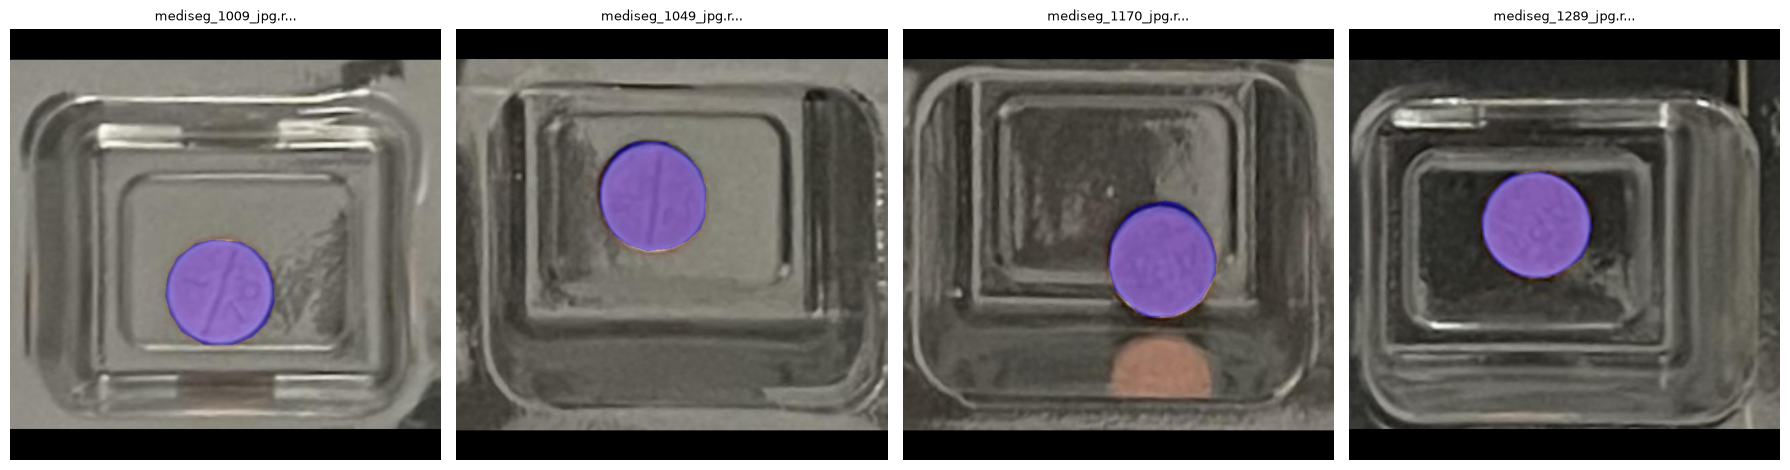

In [11]:
sample_imgs = list((OUT_DIR / "images" / "train").glob("*.*"))[:4]
fig, axes = plt.subplots(1, 4, figsize=(18, 5))

for ax, img_p in zip(axes, sample_imgs):
    img = cv2.imread(str(img_p))
    lbl_p = OUT_DIR / "labels" / "train" / f"{img_p.stem}.txt"
    h, w = img.shape[:2]
    
    overlay = img.copy()
    if lbl_p.exists():
        with open(lbl_p, "r", encoding="utf-8") as f:
            for line in f:
                parts = line.strip().split()
                if not parts:
                    continue
                cls_id = int(parts[0])
                pts = np.array(list(map(float, parts[1:])), dtype=np.float32).reshape(-1, 2)
                pts[:, 0] *= w
                pts[:, 1] *= h
                poly = pts.astype(np.int32)
                
                color = (0, 255, 0) if cls_id == 0 else (255, 0, 0)  # Зеленый: капсула, Синий: таблетка
                cv2.polylines(overlay, [poly], True, color, 3)
                cv2.fillPoly(overlay, [poly], color)
                
    img_viz = cv2.addWeighted(overlay, 0.4, img, 0.6, 0)
    ax.imshow(cv2.cvtColor(img_viz, cv2.COLOR_BGR2RGB))
    ax.set_title(img_p.name[:18] + "...", fontsize=9)
    ax.axis("off")

plt.tight_layout()
plt.show()

In [12]:
# Загружаем актуальную нано-модель сегментации YOLO26
model = YOLO("yolo26n-seg.pt")

results = model.train(
    data=str(OUT_DIR / "tabmed_seg.yaml"),
    epochs=50,
    imgsz=640,
    batch=16,
    device=0,           # RTX 4060 Ti
    workers=2,
    project=r"D:\Tabmed\Tabmed_ml\runs\segment",
    name="tabmed_yolo26n_seg",
    exist_ok=True
)

New https://pypi.org/project/ultralytics/8.4.197 available  Update with 'pip install -U ultralytics'
Ultralytics 8.4.189  Python-3.12.0 torch-2.6.0+cu124 CUDA:0 (NVIDIA GeForce RTX 4060 Ti, 16380MiB)
engine\trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=D:\Tabmed\Datasets\dataset_v6_seg\tabmed_seg.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=50, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode

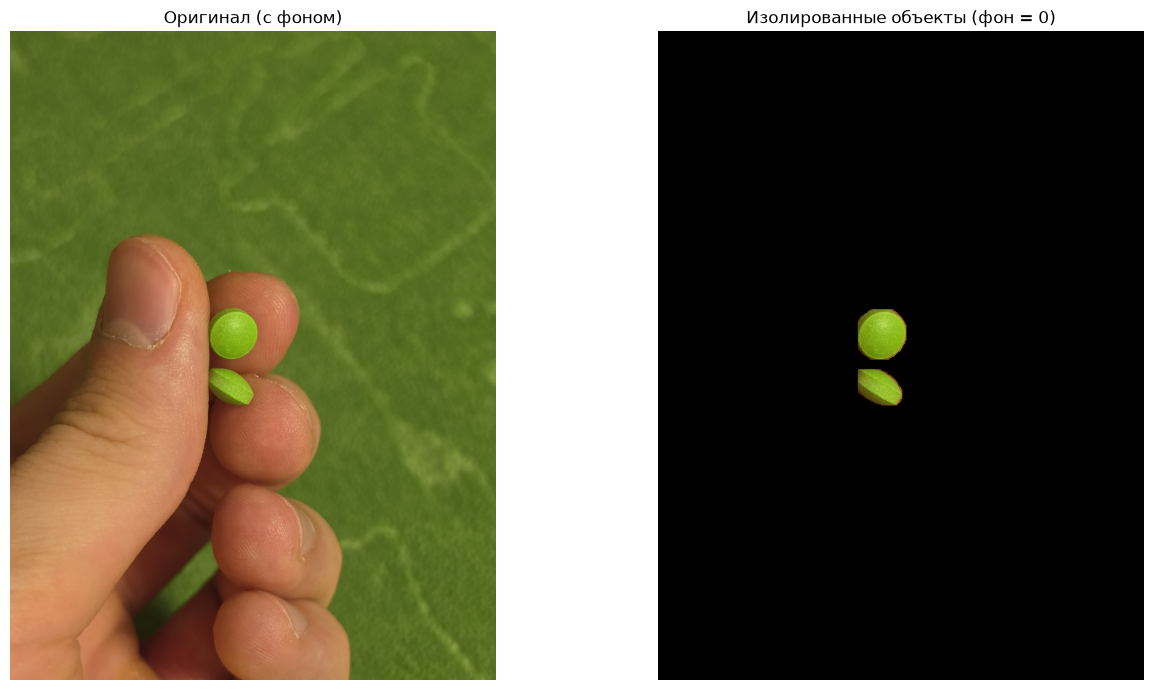

In [ ]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
from ultralytics import YOLO
from pathlib import Path

# 1. Загрузка новых весов сегментатора
WEIGHTS_PATH = Path(r"D:\Tabmed\Tabmed_ml\runs\segment\tabmed_yolo26n_seg\weights\best.pt")
model = YOLO(str(WEIGHTS_PATH))

# 2. Выбор тестового изображения (укажите путь к фото с рукой или сложным фоном)
TEST_IMG = Path(r"D:\Tabmed\Tabmed_ml\test.jpg") 

# 3. Инференс
results = model.predict(source=str(TEST_IMG), conf=0.25, verbose=False)
r = results[0]

img = cv2.imread(str(TEST_IMG))
img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

# 4. Обнуление фона
black_bg_result = np.zeros_like(img_rgb)

if r.masks is not None:
    # Извлекаем тензор масок (N, H, W)
    masks_data = r.masks.data.cpu().numpy()
    
    # Объединяем все найденные маски в одну общую бинарную маску
    combined_mask = np.any(masks_data, axis=0).astype(np.uint8) 
    
    # Ресайз маски до исходного разрешения изображения
    mask_resized = cv2.resize(combined_mask, (img_rgb.shape[1], img_rgb.shape[0]), interpolation=cv2.INTER_NEAREST)
    
    # Применяем маску: фон становится черным, объекты сохраняют цвета
    black_bg_result = cv2.bitwise_and(img_rgb, img_rgb, mask=mask_resized)

# 5. Отрисовка результата
fig, axes = plt.subplots(1, 2, figsize=(14, 7))
axes[0].imshow(img_rgb)
axes[0].set_title("Оригинал (с фоном)", fontsize=12)
axes[0].axis("off")

axes[1].imshow(black_bg_result)
axes[1].set_title("Изолированные объекты (фон = 0)", fontsize=12)
axes[1].axis("off")

plt.tight_layout()
plt.show()

Выводим 6 изображений по отдельности:

Кадр 1/6: v5_IMG_20260202_111225.jpg | Капсул: 7 | Таблеток: 1


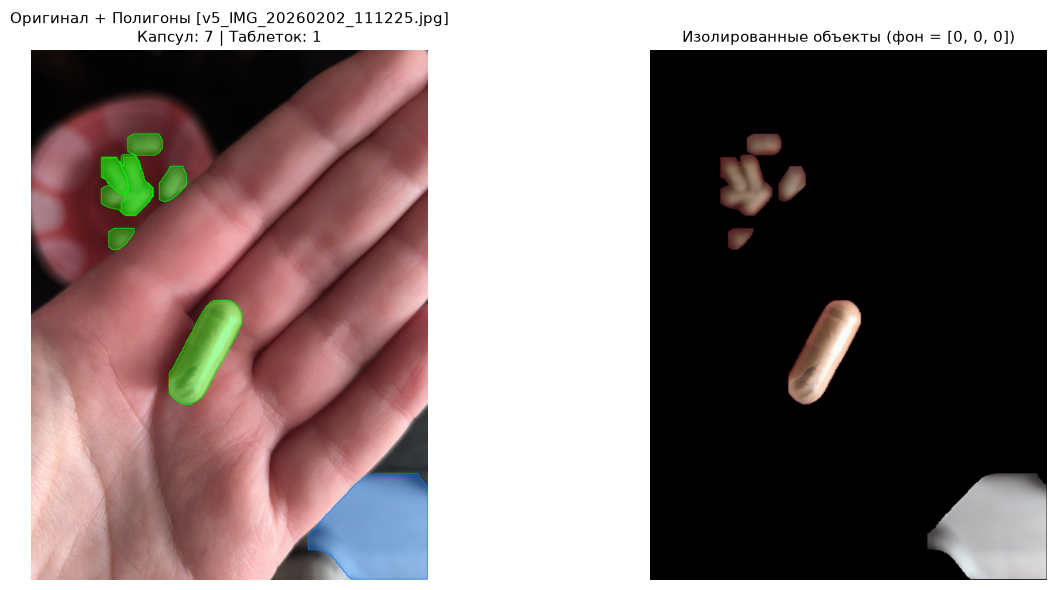

Кадр 2/6: v5_mangosteen_3773749264_jpg.rf.3f8391dc4b17d90f7317ae164440a111.jpg | Капсул: 0 | Таблеток: 52


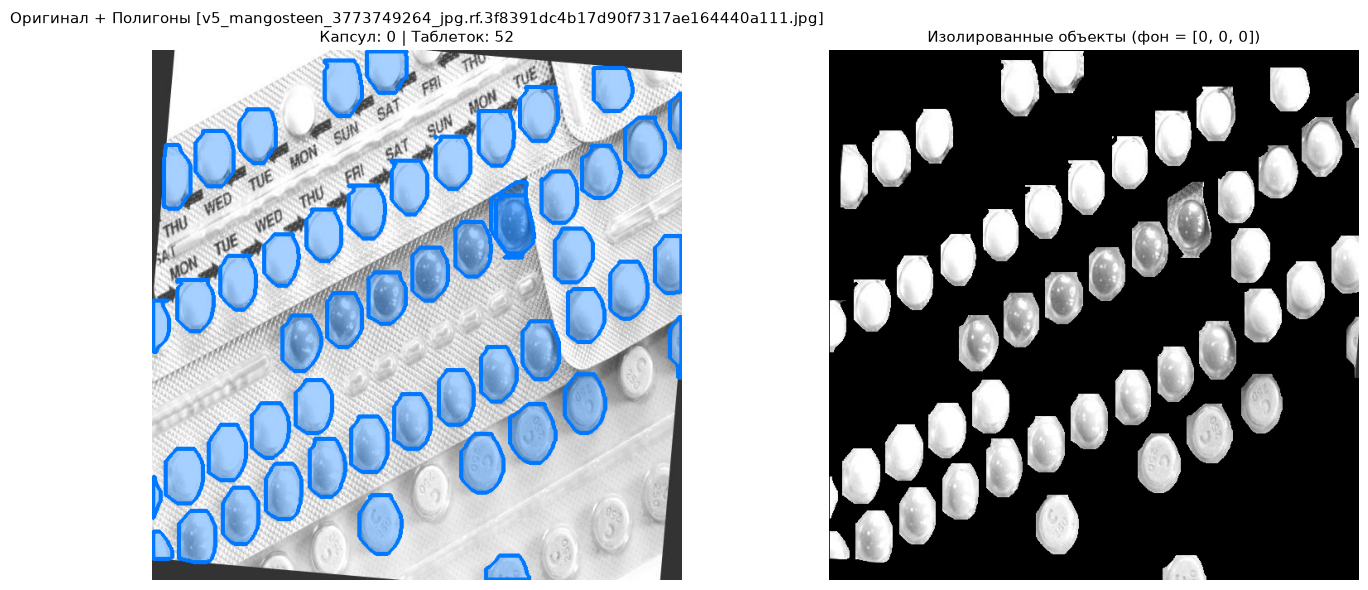

Кадр 3/6: v5_mangosteen_2364793198_jpg.rf.d7918a506372714c158a943861d00a79.jpg | Капсул: 0 | Таблеток: 11


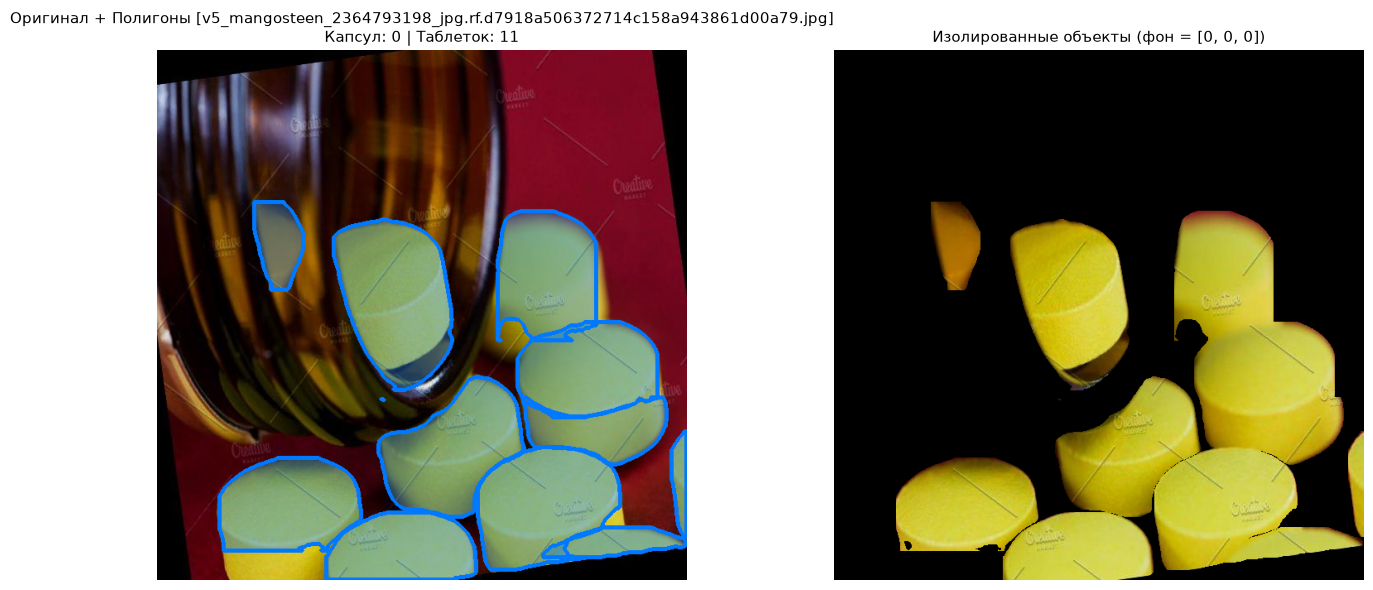

Кадр 4/6: mediseg_IMG_5633_2_jpg.rf.2ce77cb80937a79601b580d44ef3b2bb.jpg | Капсул: 0 | Таблеток: 1


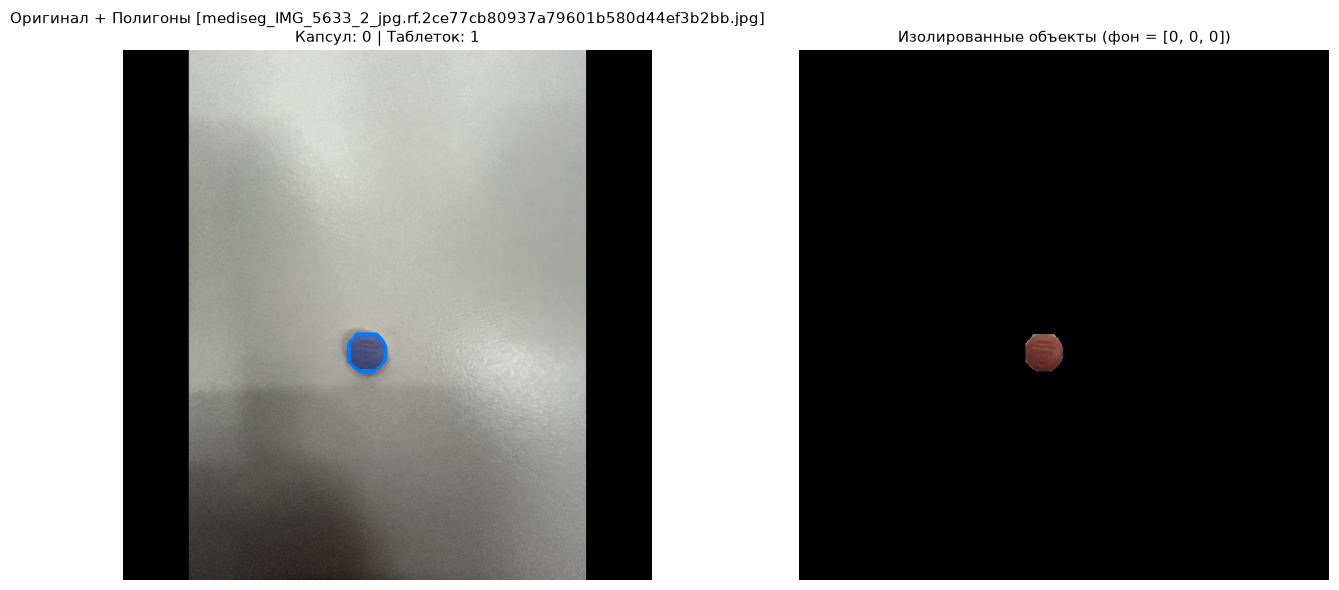

Кадр 5/6: mediseg_1440_jpg.rf.798dea3cb6c3ffac3b7e0f59fecefc2f.jpg | Капсул: 0 | Таблеток: 2


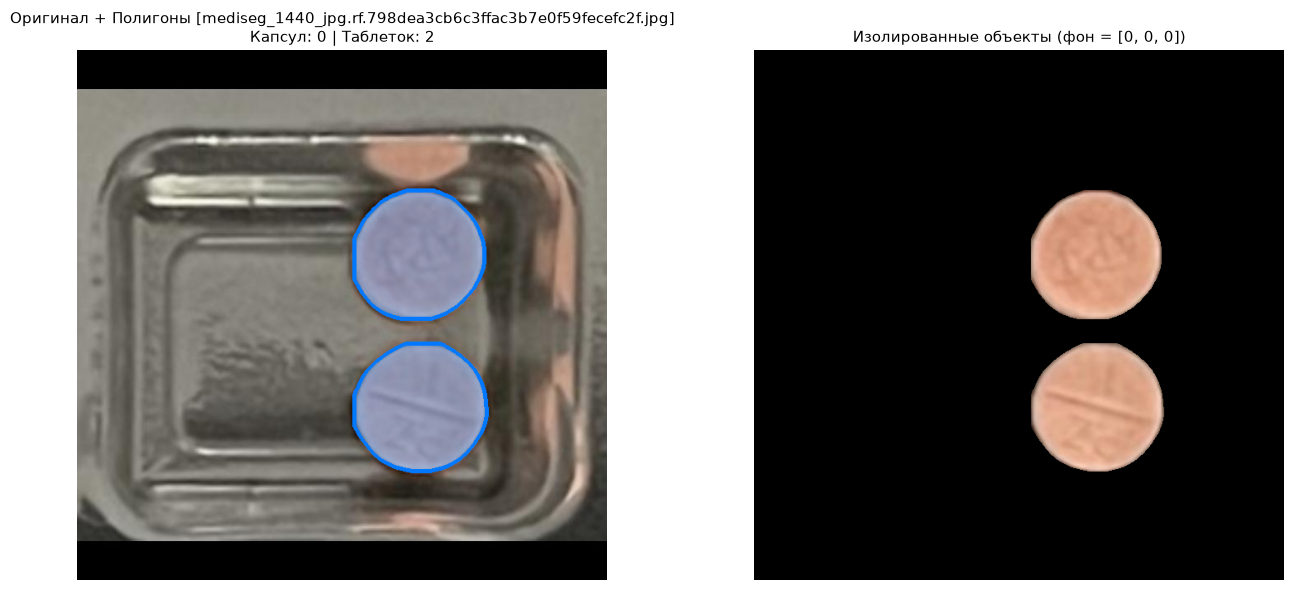

Кадр 6/6: v5_20261022_235910.jpg | Капсул: 2 | Таблеток: 0


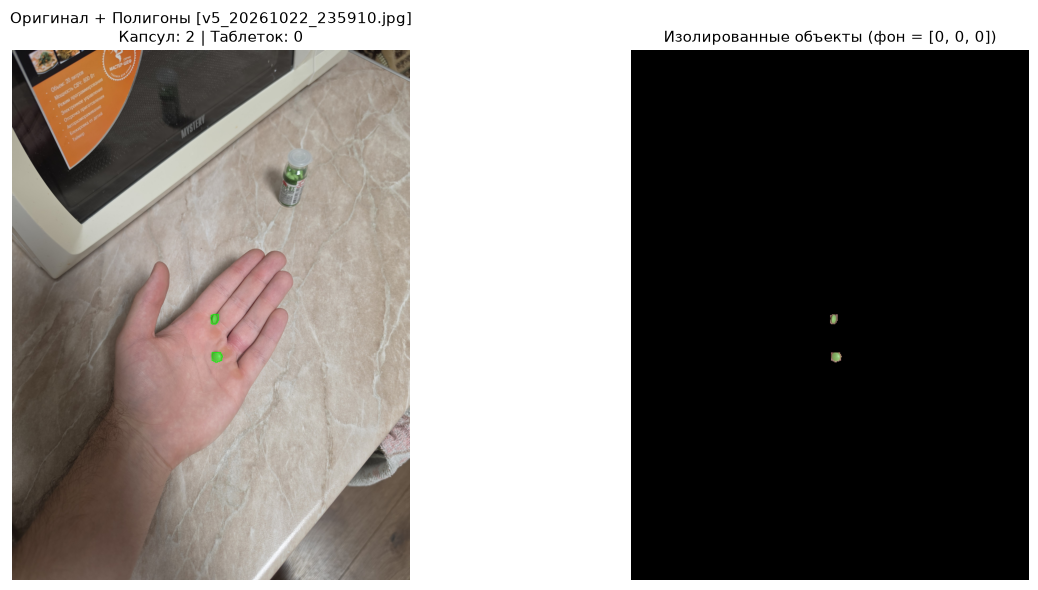

In [19]:
import random
from pathlib import Path
import cv2
import numpy as np
import matplotlib.pyplot as plt
from ultralytics import YOLO

# 1. Загрузка весов сегментатора
WEIGHTS_PATH = Path(r"D:\Tabmed\Tabmed_ml\runs\segment\tabmed_yolo26n_seg\weights\best.pt")
model = YOLO(str(WEIGHTS_PATH))

# 2. Сбор пула изображений
possible_dirs = [
    Path(r"D:\Tabmed\Datasets\dataset_v6_seg\images\val")
]

valid_exts = {".jpg", ".jpeg", ".png", ".bmp"}
candidate_files = []

for d in possible_dirs:
    if d.exists():
        for p in d.rglob("*"):
            if p.is_file() and p.suffix.lower() in valid_exts:
                if "runs" not in p.parts:
                    candidate_files.append(p)

candidate_files = list(set(candidate_files))
if not candidate_files:
    raise FileNotFoundError("Изображения не найдены на диске D:")

random.seed(42)
sampled_files = random.sample(candidate_files, min(6, len(candidate_files)))

# Цвета (BGR): 0: capsule (зеленый), 1: tablet (синий)
CLASS_COLORS = {
    0: (0, 255, 0),
    1: (255, 120, 0)
}

print(f"Выводим {len(sampled_files)} изображений по отдельности:\n")

# 3. Последовательный вывод каждого снимка отдельным крупным блоком
for idx, img_p in enumerate(sampled_files, 1):
    img = cv2.imread(str(img_p))
    if img is None:
        continue
    h, w = img.shape[:2]

    # Инференс модели
    results = model.predict(source=str(img_p), conf=0.25, verbose=False)
    r = results[0]

    annotated = img.copy()
    black_bg = np.zeros_like(img)
    counts = {"capsule": 0, "tablet": 0}

    if r.masks is not None and len(r.masks.data) > 0:
        masks_data = r.masks.data.cpu().numpy()
        combined_mask = np.zeros((h, w), dtype=np.uint8)

        for i, mask_tensor in enumerate(masks_data):
            cls_id = int(r.boxes.cls[i].item())
            cls_name = r.names[cls_id]
            counts[cls_name] = counts.get(cls_name, 0) + 1
            color = CLASS_COLORS.get(cls_id, (0, 255, 255))

            # Масштабирование маски до исходного разрешения
            mask_obj = cv2.resize(mask_tensor.astype(np.uint8), (w, h), interpolation=cv2.INTER_NEAREST)
            combined_mask = np.bitwise_or(combined_mask, mask_obj)

            # Отрисовка контуров и прозрачной заливки
            contours, _ = cv2.findContours(mask_obj, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
            cv2.polylines(annotated, contours, True, color, 3)

            overlay = annotated.copy()
            cv2.fillPoly(overlay, contours, color)
            annotated = cv2.addWeighted(overlay, 0.35, annotated, 0.65, 0)

        # Вырезание на черный фон
        black_bg = cv2.bitwise_and(img, img, mask=combined_mask)

    annotated_rgb = cv2.cvtColor(annotated, cv2.COLOR_BGR2RGB)
    black_bg_rgb = cv2.cvtColor(black_bg, cv2.COLOR_BGR2RGB)

    summary_str = f"Капсул: {counts['capsule']} | Таблеток: {counts['tablet']}"
    print(f"Кадр {idx}/{len(sampled_files)}: {img_p.name} | {summary_str}")

    # Создание отдельной широкой фигуры для текущего кадра
    fig, axes = plt.subplots(1, 2, figsize=(14, 6))
    
    axes[0].imshow(annotated_rgb)
    axes[0].set_title(f"Оригинал + Полигоны [{img_p.name}]\n{summary_str}", fontsize=11)
    axes[0].axis("off")

    axes[1].imshow(black_bg_rgb)
    axes[1].set_title("Изолированные объекты (фон = [0, 0, 0])", fontsize=11)
    axes[1].axis("off")

    plt.tight_layout()
    plt.show()